# Detección de fraude: modelos predictivos con construcción

Adaptación de [Credit Card Fraud Detection Predictive Models](credit-card-fraud-detection-predictive-models.ipynb)
al dataset del [taller de detección de anomalías](taller_detección_anomalías.ipynb).
Seguimos su recorrido: revisar los datos, explorar las variables, entrenar cinco modelos
y comparar sus resultados. El código y las conclusiones se calculan sobre nuestros datos.

**Objetivo:** ordenar las transacciones por evidencia de fraude. El desarrollo y la validación
utilizan exclusivamente `credit_card_construction.csv.zip`; después se puntúa producción
con el modelo elegido. La clase positiva es `Class = 1`.
La métrica principal es **Average Precision (AP)**, calculada con
`average_precision_score`, la medida que el taller denomina AUPR. ROC-AUC es complementaria.

Este análisis es supervisado: los cinco modelos aprenden de transacciones normales y fraudulentas.
No replica los métodos de anomalías del taller ni permite concluir cómo responderán a patrones
de fraude nuevos en producción. Tras cerrar la evaluación interna, una sección final entrena
el modelo para el envío con todo construcción y genera el CSV de scores de producción.
Producción se utiliza exclusivamente para inferencia, sin intervenir en la selección del modelo.

## Índice

1. [Paquetes y configuración](#configuracion)
2. [Carga y comprobaciones](#datos)
3. [Entrenamiento, validación y test](#particiones)
4. [Exploración de entrenamiento](#exploracion)
5. [Modelos predictivos](#modelos)
6. [Comparación en validación](#comparacion)
7. [Evaluación final en test](#test)
8. [Conclusiones y referencias](#conclusiones)
9. [Scores de producción y CSV para el profesor](#produccion)

<a id="configuracion"></a>
## 1. Paquetes y configuración

Instala `requirements.txt` en el entorno que usa el kernel antes de ejecutar.
Trabajamos en CPU, con semilla 42 y hasta cuatro hilos. Los modelos basados en árboles
no requieren escalado: conservamos las variables originales y no hacemos PCA ni remuestreo.
Las versiones mostradas documentan esta ejecución; entre versiones pueden variar los resultados.

In [1]:
import os

RANDOM_STATE = 42
N_JOBS = 4
N_ESTIMATORS = 100
MAX_ITERATIONS = 500
EARLY_STOPPING_ROUNDS = 50
THRESHOLD = 0.5

# Limitar también los hilos de las bibliotecas numéricas antes de importarlas.
for variable in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS", "NUMEXPR_NUM_THREADS"):
    os.environ[variable] = str(N_JOBS)

from importlib.metadata import version
from pathlib import Path
from time import perf_counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from sklearn.metrics import (
    average_precision_score, roc_auc_score, precision_recall_curve, roc_curve,
    precision_score, recall_score, f1_score, ConfusionMatrixDisplay,
)
from sklearn.model_selection import StratifiedGroupKFold
from threadpoolctl import threadpool_limits
from catboost import CatBoostClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier, early_stopping, log_evaluation

%matplotlib inline
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.2})
pd.set_option("display.max_columns", 30)

display(pd.Series(
    {name: version(name) for name in (
        "numpy", "pandas", "matplotlib", "scikit-learn", "catboost", "xgboost", "lightgbm"
    )}, name="Versión"
).to_frame())

,Versión
numpy,2.5.4
pandas,3.0.6
matplotlib,3.11.2
scikit-learn,1.9.1
catboost,1.2.10
xgboost,3.4.1
lightgbm,4.7.0


<a id="datos"></a>
## 2. Carga y comprobaciones

Leemos el ZIP de construcción directamente, sin descargar ni extraer archivos.
Frente al notebook de referencia, aquí hay **20 variables `X` y `Amount`**:
no existen `Time`, `Hour` ni `V1`–`V28`. Por ello no reproducimos sus gráficos temporales
ni trasladamos interpretaciones sobre aquellas variables.

In [2]:
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_PATH = PROJECT_ROOT / "data" / "credit_card_construction.csv.zip"
if not DATA_PATH.is_file():
    raise FileNotFoundError(f"No se encuentra el ZIP de construcción: {DATA_PATH}")

PREDICTORS = [f"X{i}" for i in range(1, 21)] + ["Amount"]
TARGET = "Class"
df_const = pd.read_csv(DATA_PATH, compression="zip", low_memory=False)

assert df_const.columns.is_unique, "Hay nombres de columna duplicados."
assert set(df_const.columns) == set(PREDICTORS + [TARGET]), "El esquema no es el esperado."
assert all(pd.api.types.is_numeric_dtype(df_const[c]) for c in PREDICTORS + [TARGET])
assert not df_const.isna().any().any(), "Hay nulos: revisar antes de entrenar."
assert np.isfinite(df_const[PREDICTORS + [TARGET]].to_numpy()).all(), "Hay valores no finitos."
assert set(df_const[TARGET].unique()) == {0, 1}, "Class debe contener ambas clases: 0 y 1."

print(f"Construcción: {len(df_const):,} transacciones y {len(PREDICTORS)} predictores.")
display(df_const.head())
display(pd.DataFrame({
    "tipo": df_const.dtypes.astype(str),
    "nulos": df_const.isna().sum(),
    "no_finitos": (~np.isfinite(df_const)).sum(),
}))
display(df_const[TARGET].value_counts().sort_index().rename("Transacciones").to_frame().assign(
    Porcentaje=lambda table: 100 * table["Transacciones"] / len(df_const)
))
print(f"Filas duplicadas completas, después de la primera aparición: {df_const.duplicated().sum():,}")

Construcción: 170,884 transacciones y 21 predictores.


,X1,X2,X3,X4,X5,X6,X7,X8,X9,X10,X11,X12,X13,X14,X15,X16,X17,X18,X19,X20,Amount,Class
0,374.0,-288.0,-150.0,-232.0,-90.0,262.0,-262.0,88.0,-26.0,152.0,212.0,60.0,98.0,-50.0,134.0,178.0,64.0,-322.0,-58.0,20.0,144.00,0
1,436.0,-202.0,-566.0,-652.0,166.0,58.0,-18.0,-0.0,54.0,-54.0,214.0,214.0,-2.0,198.0,248.0,-688.0,108.0,100.0,-34.0,-136.0,10.46,0
2,388.0,-128.0,-56.0,30.0,-114.0,104.0,-210.0,72.0,298.0,2.0,28.0,78.0,-168.0,22.0,82.0,172.0,-218.0,222.0,36.0,-40.0,31.72,0
3,-486.0,4.0,314.0,-80.0,-276.0,-94.0,-34.0,94.0,-252.0,2.0,-198.0,-24.0,116.0,8.0,138.0,-110.0,-86.0,326.0,-358.0,-182.0,134.85,0
4,258.0,-238.0,300.0,-70.0,-374.0,122.0,-350.0,92.0,134.0,94.0,4.0,-40.0,-260.0,-192.0,-382.0,182.0,120.0,-120.0,282.0,-6.0,8.70,0


,tipo,nulos,no_finitos
X1,float64,0,0
X2,float64,0,0
X3,float64,0,0
X4,float64,0,0
X5,float64,0,0
X6,float64,0,0
X7,float64,0,0
X8,float64,0,0
X9,float64,0,0
X10,float64,0,0


,Transacciones,Porcentaje
Class,,
0,170589,99.827368
1,295,0.172632


Filas duplicadas completas, después de la primera aparición: 4,167


<a id="particiones"></a>
## 3. Entrenamiento, validación y test sin duplicados compartidos

Una división aleatoria por filas puede dejar transacciones idénticas en entrenamiento y test,
inflando la evaluación. Conservamos todas las filas, pero agrupamos por los **21 predictores**,
sin usar la etiqueta para definir la identidad de una transacción.

Usamos el primer reparto de `StratifiedGroupKFold` con cinco particiones para reservar
aproximadamente un 20 % como test. Sobre el 80 % restante, el primer reparto con cuatro
particiones reserva validación. El resultado se aproxima a **60/20/20**; los grupos completos
impiden garantizar porcentajes exactos. No es una evaluación por validación cruzada:
solo aprovechamos el algoritmo de reparto estratificado con grupos.

Validación servirá para parada temprana y selección del modelo. Test queda reservado para
una única evaluación final; de él solo comprobamos aquí el tamaño y la presencia de ambas clases.

In [3]:
X = df_const[PREDICTORS]
y = df_const[TARGET].astype(int)
groups = df_const.groupby(PREDICTORS, sort=False, dropna=False).ngroup().to_numpy()
assert y.groupby(groups).nunique().max() == 1, "Hay transacciones idénticas con etiquetas contradictorias."

outer_split = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
idx_dev, idx_test = next(outer_split.split(X, y, groups))
inner_split = StratifiedGroupKFold(n_splits=4, shuffle=True, random_state=RANDOM_STATE)
train_relative, valid_relative = next(inner_split.split(
    X.iloc[idx_dev], y.iloc[idx_dev], groups[idx_dev]
))
idx_train, idx_valid = idx_dev[train_relative], idx_dev[valid_relative]
split_indices = {"Entrenamiento": idx_train, "Validación": idx_valid, "Test": idx_test}

joined_indices = np.concatenate(list(split_indices.values()))
assert len(joined_indices) == len(df_const)
assert np.array_equal(np.sort(joined_indices), np.arange(len(df_const)))
group_sets = {name: set(groups[idx]) for name, idx in split_indices.items()}
names = list(split_indices)
for i, name in enumerate(names):
    assert set(y.iloc[split_indices[name]].unique()) == {0, 1}
    for other in names[i + 1:]:
        assert group_sets[name].isdisjoint(group_sets[other]), f"Grupos compartidos: {name}, {other}"

partition_summary = pd.DataFrame([
    {
        "Partición": name, "Transacciones": len(idx), "% del total": 100 * len(idx) / len(y),
        "Normales": int(y.iloc[idx].eq(0).sum()), "Fraudes": int(y.iloc[idx].sum()),
        "% fraude": 100 * y.iloc[idx].mean(), "Grupos": len(group_sets[name]),
    }
    for name, idx in split_indices.items()
]).set_index("Partición")
display(partition_summary.round(4))
print("Comprobado: cobertura completa, ambas clases y ningún grupo compartido entre particiones.")

X_train, y_train = X.iloc[idx_train], y.iloc[idx_train]
X_valid, y_valid = X.iloc[idx_valid], y.iloc[idx_valid]

,Transacciones,% del total,Normales,Fraudes,% fraude,Grupos
Partición,,,,,,
Entrenamiento,102530,59.9998,102353,177,0.1726,100030
Validación,34177,20.0001,34118,59,0.1726,33344
Test,34177,20.0001,34118,59,0.1726,33343


Comprobado: cobertura completa, ambas clases y ningún grupo compartido entre particiones.


<a id="exploracion"></a>
## 4. Exploración de entrenamiento

Todas las estadísticas y gráficos siguientes usan **solo entrenamiento**.
No eliminamos observaciones extremas: pueden contener la señal del fraude.

,count,mean,std,min,25%,50%,75%,max
X1,102530.0,-0.076582,392.948887,-11282.0,-184.00,2.00,264.0,490.0
X2,102530.0,-0.913138,333.824141,-14544.0,-120.00,12.00,160.0,4294.0
X3,102530.0,2.153340,302.915526,-6594.0,-176.00,38.00,208.0,1876.0
X4,102530.0,-0.743802,282.637749,-1084.0,-170.00,-4.00,148.0,3344.0
X5,102530.0,-0.453760,271.453354,-5764.0,-138.00,-12.00,120.0,6960.0
X6,102530.0,-0.473344,263.298067,-5232.0,-154.00,-54.00,80.0,4238.0
X7,102530.0,-0.424617,242.693861,-8302.0,-112.00,8.00,114.0,5700.0
X8,102530.0,0.152775,243.185309,-14644.0,-42.00,4.00,66.0,3918.0
X9,102530.0,-0.487311,219.000575,-2686.0,-130.00,-10.00,118.0,3118.0
X10,102530.0,-0.102721,216.767792,-4880.0,-106.00,-18.00,92.0,4750.0


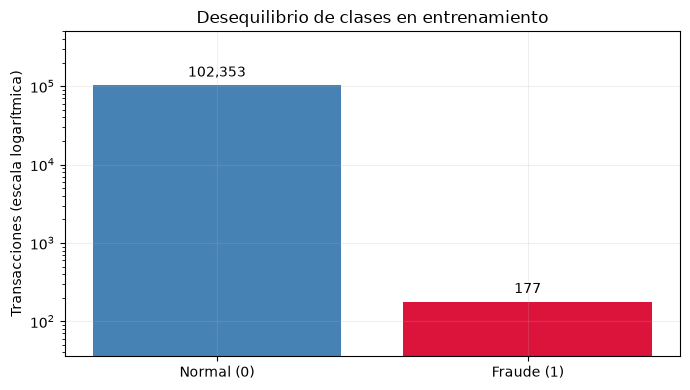

AP de referencia para un ranking aleatorio: prevalencia de fraude = 0.001726.


In [4]:
train_df = df_const.iloc[idx_train]
display(train_df.describe().T)

counts = y_train.value_counts().sort_index()
fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(["Normal (0)", "Fraude (1)"], counts.values, color=["steelblue", "crimson"])
ax.set_yscale("log")
ax.bar_label(bars, labels=[f"{n:,}" for n in counts.values], padding=4)
ax.set(ylabel="Transacciones (escala logarítmica)", title="Desequilibrio de clases en entrenamiento")
ax.margins(y=0.25)
fig.tight_layout()
plt.show()
print(f"AP de referencia para un ranking aleatorio: prevalencia de fraude = {y_train.mean():.6f}.")

### Dispersión de `X1` y `X2`

Mostramos hasta 10.000 normales elegidas con semilla fija y todos los fraudes de entrenamiento.
Esta muestra permite ver ambas clases, pero altera su proporción visual; no representa la prevalencia.
Dos variables tampoco resumen toda la información que reciben los modelos.

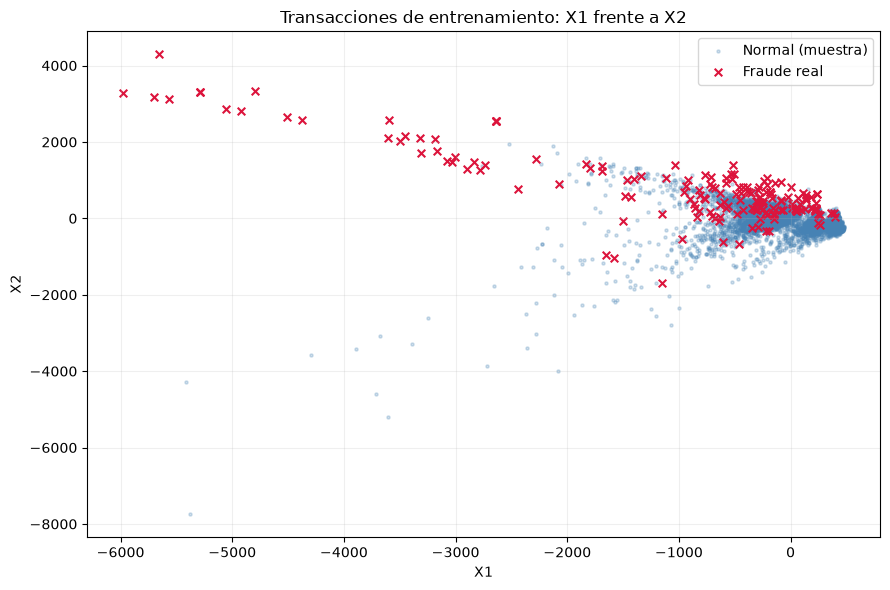

In [5]:
normal_train = train_df.loc[train_df[TARGET].eq(0)]
fraud_train = train_df.loc[train_df[TARGET].eq(1)]
normal_sample = normal_train.sample(n=min(10_000, len(normal_train)), random_state=RANDOM_STATE)

fig, ax = plt.subplots(figsize=(9, 6))
ax.scatter(normal_sample["X1"], normal_sample["X2"], s=5, alpha=0.25, color="steelblue", label="Normal (muestra)")
ax.scatter(fraud_train["X1"], fraud_train["X2"], s=30, marker="x", color="crimson", label="Fraude real")
ax.set(xlabel="X1", ylabel="X2", title="Transacciones de entrenamiento: X1 frente a X2")
ax.legend()
fig.tight_layout()
plt.show()

### Importe de las transacciones

La tabla conserva todos los valores. El histograma usa el mismo intervalo de bins para ambas
clases y normaliza cada clase por separado. Su eje vertical logarítmico permite apreciar las colas.
El boxplot oculta únicamente los puntos extremos en el dibujo, sin eliminarlos de los datos.

,count,mean,std,min,25%,50%,75%,max
Class,,,,,,,,
0,102353.0,131.981725,366.954301,0.0,8.79,33.51,114.04,29484.80
1,177.0,168.818983,361.046999,0.0,1.50,12.96,149.98,2714.52


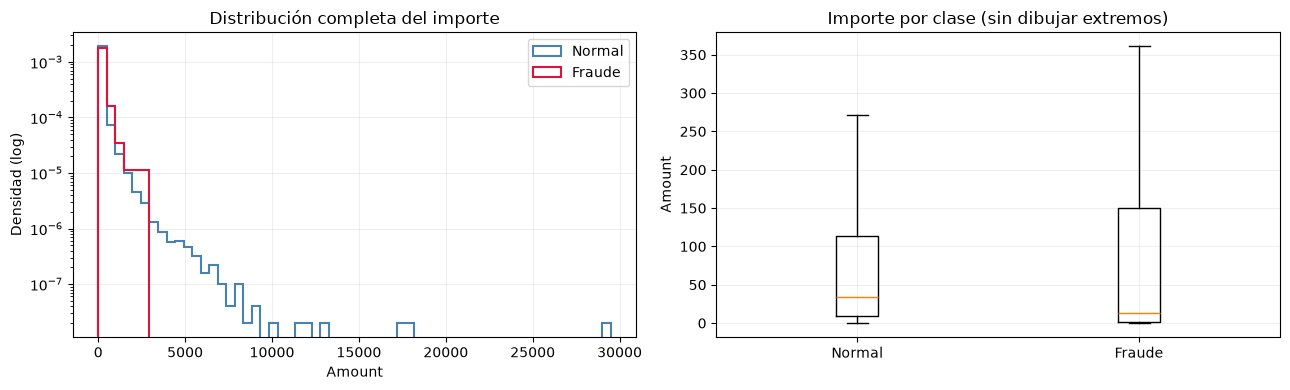

In [6]:
display(train_df.groupby(TARGET)["Amount"].describe())
amounts = [normal_train["Amount"].to_numpy(), fraud_train["Amount"].to_numpy()]
amount_bins = np.histogram_bin_edges(train_df["Amount"], bins=60)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for values, label, color in zip(amounts, ["Normal", "Fraude"], ["steelblue", "crimson"]):
    axes[0].hist(values, bins=amount_bins, density=True, histtype="step", linewidth=1.5, label=label, color=color)
axes[0].set(yscale="log", xlabel="Amount", ylabel="Densidad (log)", title="Distribución completa del importe")
axes[0].legend()
axes[1].boxplot(amounts, showfliers=False)
axes[1].set_xticks([1, 2], ["Normal", "Fraude"])
axes[1].set(ylabel="Amount", title="Importe por clase (sin dibujar extremos)")
fig.tight_layout()
plt.show()

### Correlaciones y distribuciones por clase

La correlación de Pearson describe relaciones lineales, no la importancia predictiva ni causalidad.
Las variables se conservan todas. En los histogramas, cada clase tiene densidad total uno:
se comparan formas y no recuentos. Usamos bins compartidos en el rango completo de entrenamiento.

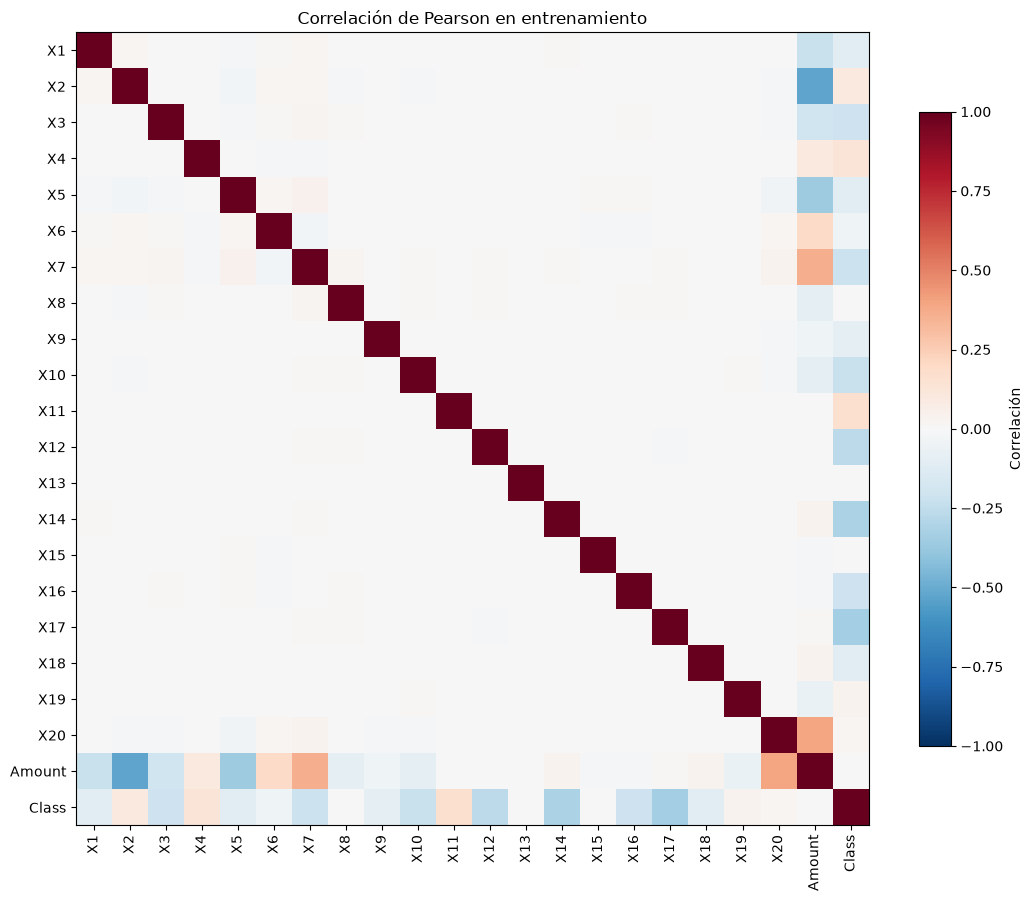

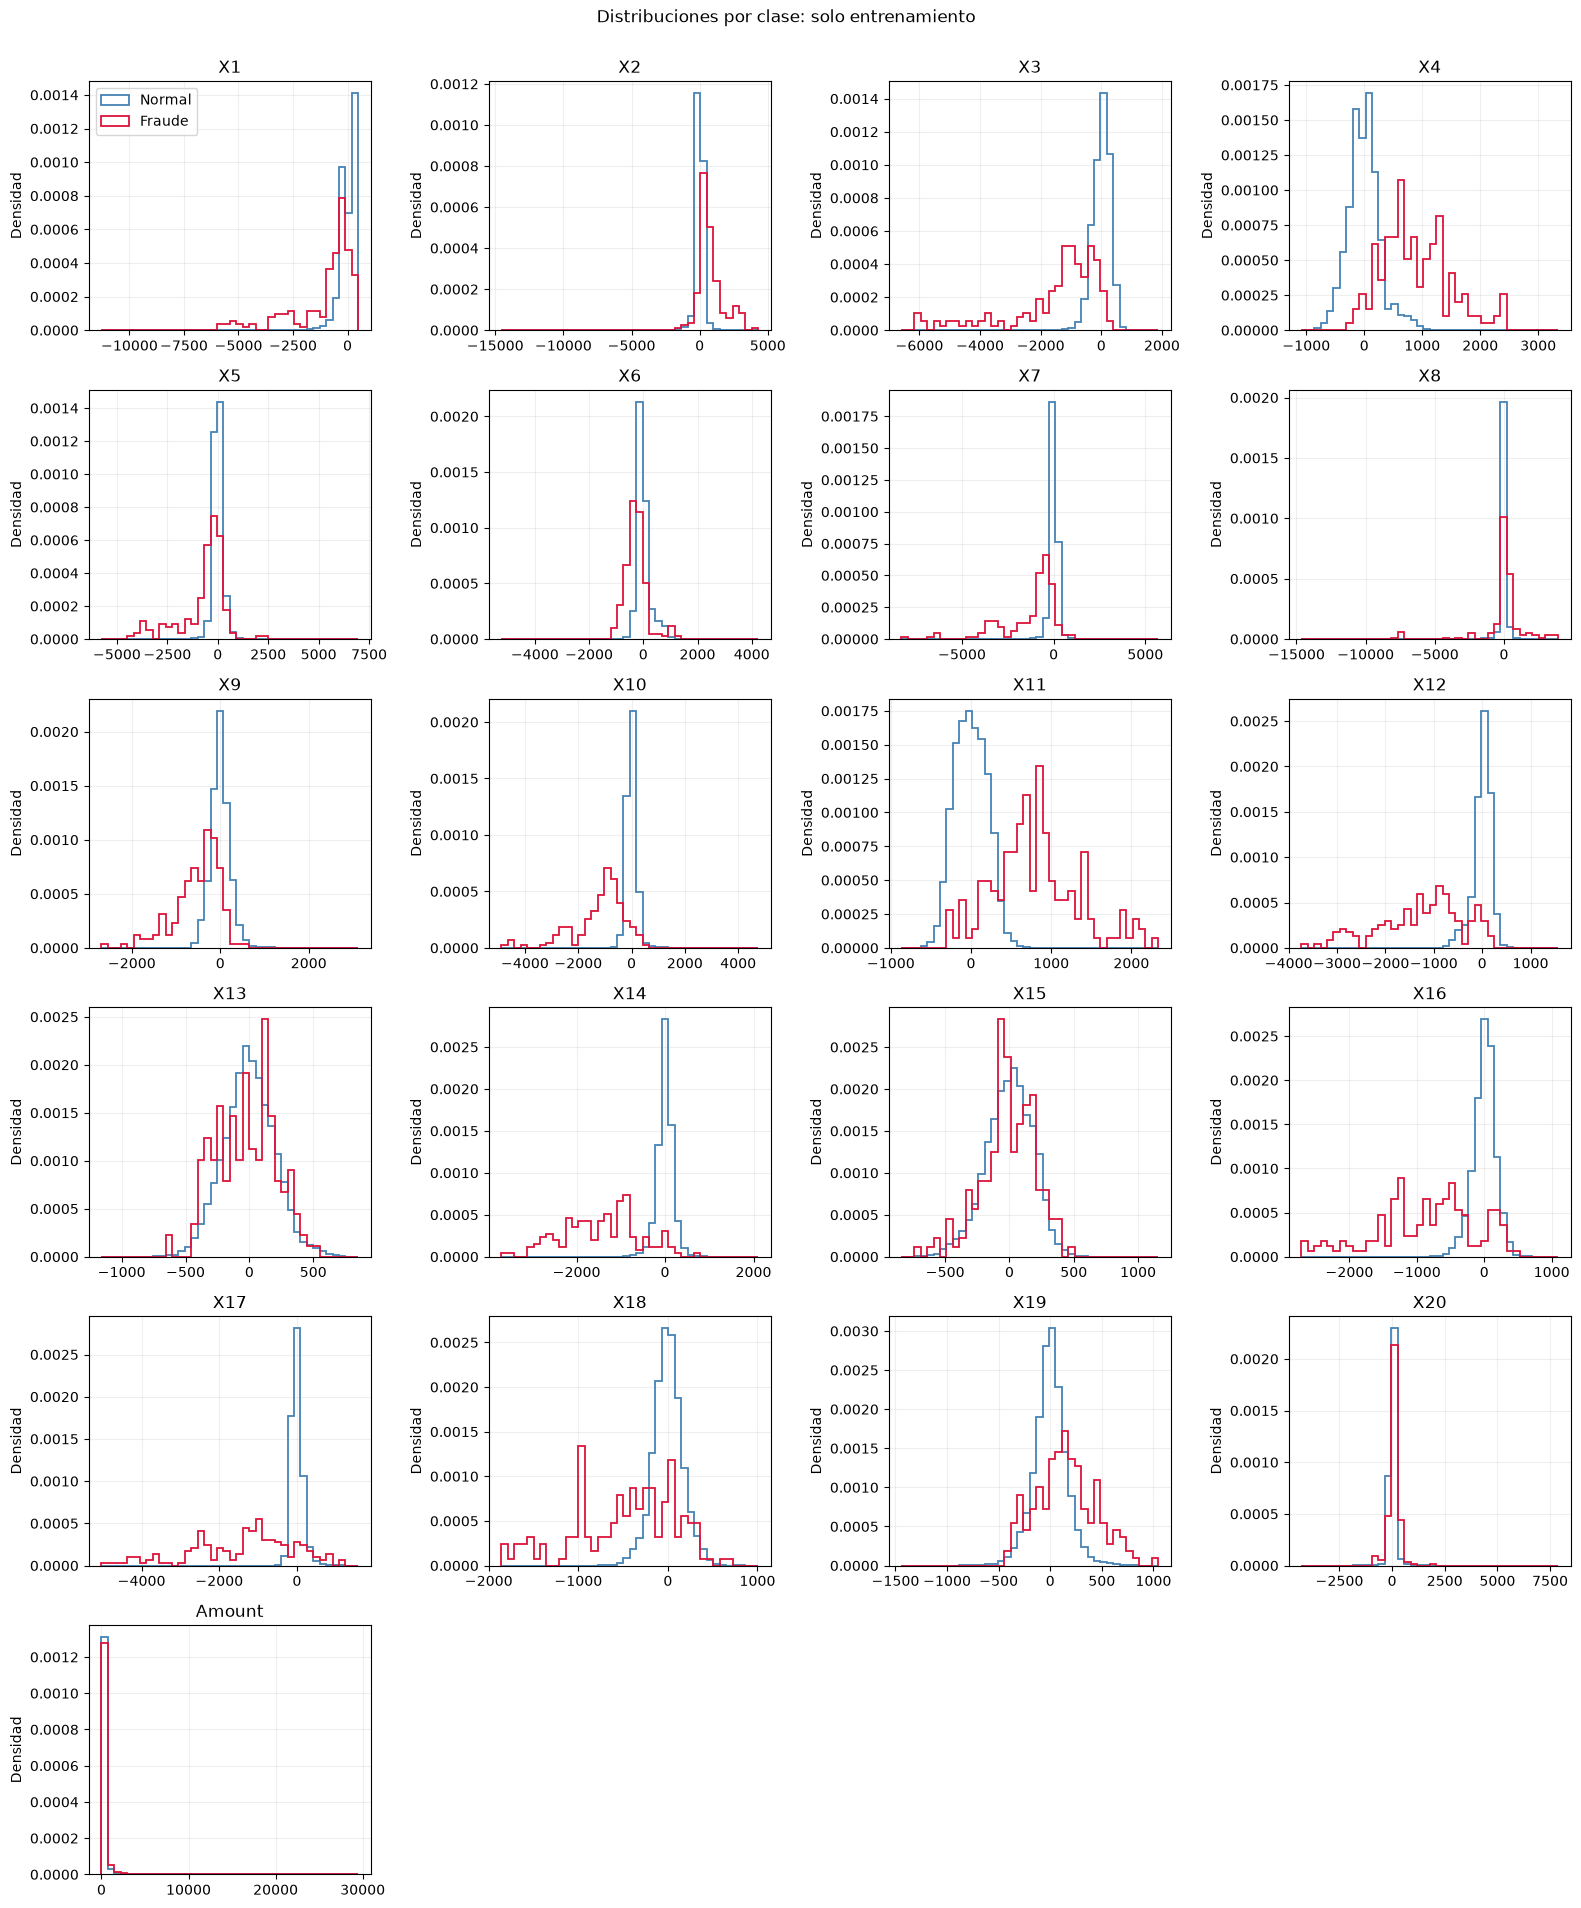

In [7]:
corr = train_df[PREDICTORS + [TARGET]].corr()
fig, ax = plt.subplots(figsize=(11, 9))
image = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=90)
ax.set_yticks(range(len(corr)), corr.columns)
ax.grid(False)
ax.set_title("Correlación de Pearson en entrenamiento")
fig.colorbar(image, ax=ax, shrink=0.8, label="Correlación")
fig.tight_layout()
plt.show()

fig, axes = plt.subplots(6, 4, figsize=(16, 19))
for ax, feature in zip(axes.flat, PREDICTORS):
    bins = np.histogram_bin_edges(train_df[feature], bins=40)
    for frame, label, color in (
        (normal_train, "Normal", "steelblue"), (fraud_train, "Fraude", "crimson")
    ):
        ax.hist(frame[feature], bins=bins, density=True, histtype="step", linewidth=1.3, color=color, label=label)
    ax.set(title=feature, ylabel="Densidad")
axes.flat[0].legend()
for ax in list(axes.flat)[len(PREDICTORS):]:
    ax.set_visible(False)
fig.suptitle("Distribuciones por clase: solo entrenamiento", y=1.002)
fig.tight_layout()
plt.show()

<a id="modelos"></a>
## 5. Modelos predictivos

Todos los modelos reciben los mismos predictores y particiones, con ambas clases y sin ponderación
ni remuestreo. Son configuraciones iniciales moderadas, no una búsqueda del mejor hiperparámetro.

Para CatBoost, XGBoost y LightGBM fijamos un máximo de 500 iteraciones y paciencia de 50.
La parada temprana monitoriza **ROC-AUC de validación** en los tres casos. La selección entre
modelos usa después **AP de validación**, calculada de forma uniforme con scikit-learn.
El uso compartido de validación implica que sus métricas son de desarrollo; test ofrecerá la
evaluación final del procedimiento de selección.

Las importancias se normalizan dentro de cada modelo y describen su uso de las variables.
No son causales, no tienen por qué coincidir entre algoritmos y pueden favorecer variables
con muchas posibilidades de corte.

In [8]:
models = {}
validation_scores = {}
validation_rows = []
selected_iterations = {}


def check_scores(scores, expected_rows):
    scores = np.asarray(scores, dtype=float)
    assert scores.shape == (expected_rows,), "Debe haber un score por transacción."
    assert np.isfinite(scores).all(), "Los scores deben ser finitos."
    assert ((scores >= 0) & (scores <= 1)).all(), "Se esperaban probabilidades entre 0 y 1."
    return scores


def measure_scores(labels, scores):
    predictions = (scores >= THRESHOLD).astype(int)
    metrics = {
        "AP": average_precision_score(labels, scores),
        "ROC-AUC": roc_auc_score(labels, scores),
        "Precision@0.5": precision_score(labels, predictions, zero_division=0),
        "Recall@0.5": recall_score(labels, predictions, zero_division=0),
        "F1@0.5": f1_score(labels, predictions, zero_division=0),
    }
    assert all(np.isfinite(v) and 0 <= v <= 1 for v in metrics.values())
    return metrics


def record_validation(name, model, elapsed_seconds, iterations):
    assert list(model.classes_) == [0, 1], "La columna 1 debe corresponder a fraude."
    prediction_kwargs = {"thread_count": N_JOBS} if name == "CatBoost" else {}
    scores = check_scores(model.predict_proba(X_valid, **prediction_kwargs)[:, 1], len(y_valid))
    models[name] = model
    validation_scores[name] = scores
    selected_iterations[name] = int(iterations)
    assert 1 <= iterations <= (N_ESTIMATORS if name in ("Random Forest", "AdaBoost") else MAX_ITERATIONS)
    row = {
        "Modelo": name, "Orden": len(validation_rows), **measure_scores(y_valid, scores),
        "Iteraciones": int(iterations), "Segundos de ajuste": elapsed_seconds,
    }
    validation_rows.append(row)
    display(pd.DataFrame([row]).drop(columns="Orden").set_index("Modelo").round(6))

    importance = pd.Series(np.asarray(model.feature_importances_, dtype=float), index=PREDICTORS)
    assert np.isfinite(importance).all() and (importance >= 0).all()
    if importance.sum() > 0:
        importance = importance / importance.sum()
    importance = importance.sort_values()
    fig, ax = plt.subplots(figsize=(8, 6))
    ax.barh(importance.index, importance.values, color="steelblue")
    ax.set(xlabel="Importancia normalizada en el modelo", title=f"{name}: importancia de variables")
    fig.tight_layout()
    plt.show()

### 5.1. Random Forest

Combina 100 árboles entrenados sobre muestras bootstrap y subconjuntos de variables.
Conservamos profundidad libre y `max_features="sqrt"`. Su probabilidad de fraude combina
las probabilidades de los árboles, en lugar de usar etiquetas binarias para calcular AP o ROC-AUC.

,AP,ROC-AUC,Precision@0.5,Recall@0.5,F1@0.5,Iteraciones,Segundos de ajuste
Modelo,,,,,,,
Random Forest,0.798778,0.939061,0.918367,0.762712,0.833333,100,6.496993


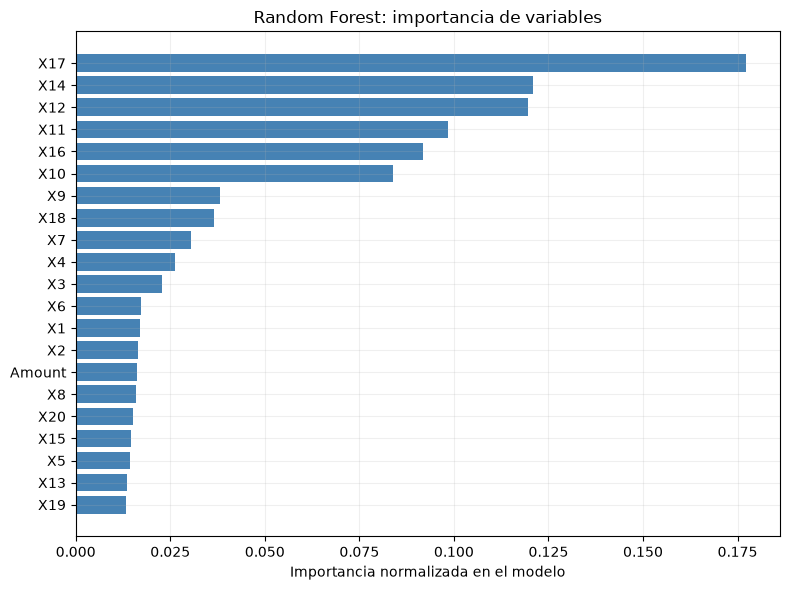

In [9]:
rf_model = RandomForestClassifier(
    n_estimators=N_ESTIMATORS, criterion="gini", max_features="sqrt",
    random_state=RANDOM_STATE, n_jobs=N_JOBS,
)
start = perf_counter()
with threadpool_limits(limits=N_JOBS):
    rf_model.fit(X_train, y_train)
elapsed = perf_counter() - start
record_validation("Random Forest", rf_model, elapsed, len(rf_model.estimators_))

### 5.2. AdaBoost

Entrena secuencialmente árboles de un solo nivel, aumentando el peso de los casos difíciles.
Usamos 100 estimadores y tasa de aprendizaje 0,8. Empleamos la API actual de scikit-learn,
sin el argumento antiguo `algorithm="SAMME.R"` de la referencia. Es un método secuencial;
no ofrece un parámetro `n_jobs`.

,AP,ROC-AUC,Precision@0.5,Recall@0.5,F1@0.5,Iteraciones,Segundos de ajuste
Modelo,,,,,,,
AdaBoost,0.683423,0.982459,0.764706,0.661017,0.709091,100,15.137829


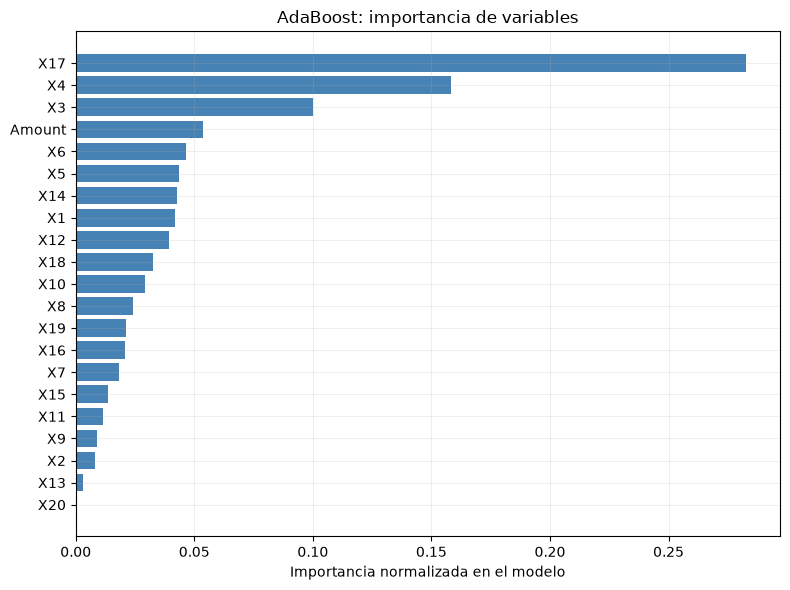

In [10]:
ada_model = AdaBoostClassifier(
    n_estimators=N_ESTIMATORS, learning_rate=0.8, random_state=RANDOM_STATE,
)
start = perf_counter()
with threadpool_limits(limits=N_JOBS):
    ada_model.fit(X_train, y_train)
elapsed = perf_counter() - start
record_validation("AdaBoost", ada_model, elapsed, len(ada_model.estimators_))

### 5.3. CatBoost

Boosting con árboles de profundidad 6, tasa de aprendizaje 0,05 y pérdida logística.
Aunque CatBoost admite variables categóricas, aquí todas son numéricas.
`use_best_model=True` conserva los árboles de la mejor iteración de validación.
Desactivamos la escritura de archivos auxiliares de CatBoost.

,AP,ROC-AUC,Precision@0.5,Recall@0.5,F1@0.5,Iteraciones,Segundos de ajuste
Modelo,,,,,,,
CatBoost,0.708014,0.984679,0.903226,0.474576,0.622222,7,1.262518


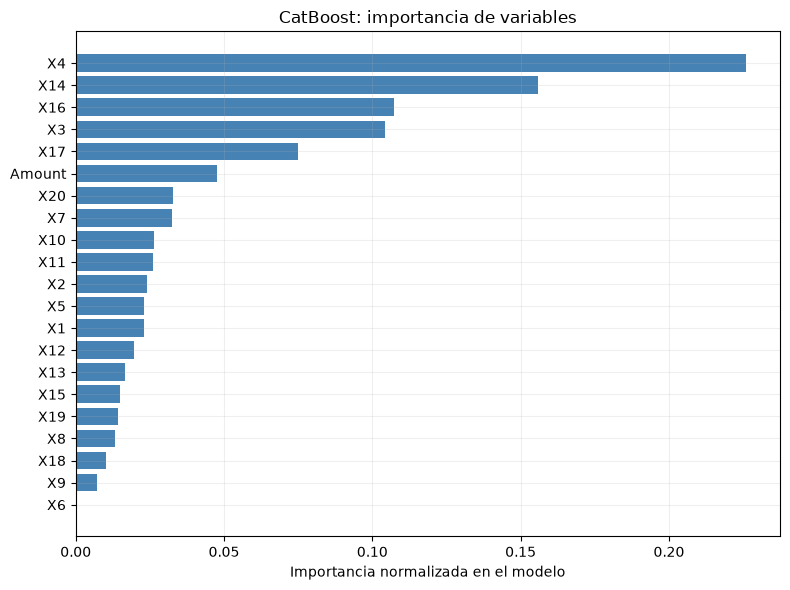

In [11]:
cat_model = CatBoostClassifier(
    iterations=MAX_ITERATIONS, depth=6, learning_rate=0.05,
    loss_function="Logloss", eval_metric="AUC", random_seed=RANDOM_STATE,
    thread_count=N_JOBS, task_type="CPU", allow_writing_files=False, verbose=False,
)
start = perf_counter()
with threadpool_limits(limits=N_JOBS):
    cat_model.fit(
        X_train, y_train, eval_set=(X_valid, y_valid),
        early_stopping_rounds=EARLY_STOPPING_ROUNDS, use_best_model=True, verbose=False,
    )
elapsed = perf_counter() - start
record_validation("CatBoost", cat_model, elapsed, cat_model.tree_count_)

### 5.4. XGBoost

Boosting de profundidad 4, tasa de aprendizaje 0,05 y construcción por histogramas en CPU.
Muestreamos un 80 % de las filas y un 90 % de las variables en cada iteración.
La parada temprana se configura en el constructor; `predict_proba` utiliza automáticamente
la mejor iteración. El índice `best_iteration` empieza en cero, por eso sumamos uno al contar árboles.

,AP,ROC-AUC,Precision@0.5,Recall@0.5,F1@0.5,Iteraciones,Segundos de ajuste
Modelo,,,,,,,
XGBoost,0.739782,0.979821,0.0,0.0,0.0,5,0.623802


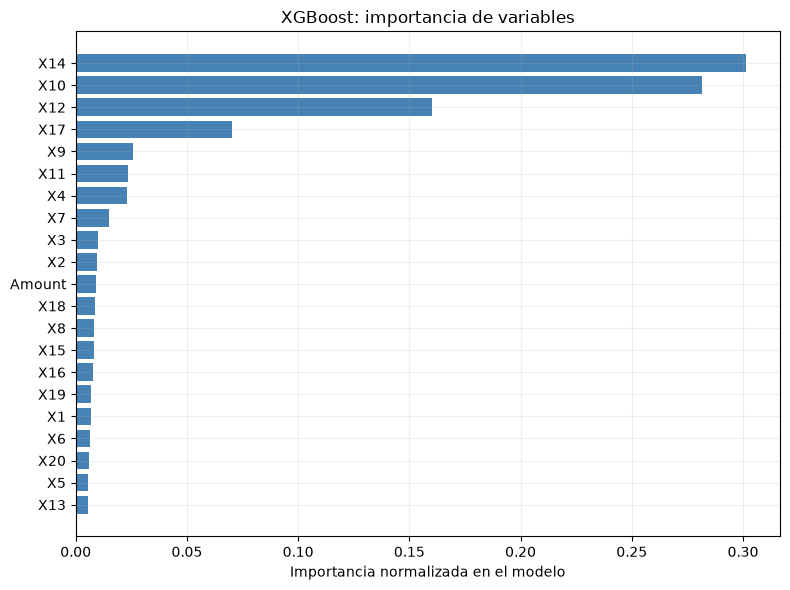

In [12]:
xgb_model = XGBClassifier(
    n_estimators=MAX_ITERATIONS, max_depth=4, learning_rate=0.05,
    subsample=0.8, colsample_bytree=0.9, objective="binary:logistic",
    tree_method="hist", device="cpu", eval_metric="auc",
    early_stopping_rounds=EARLY_STOPPING_ROUNDS, random_state=RANDOM_STATE,
    n_jobs=N_JOBS, verbosity=0,
)
start = perf_counter()
with threadpool_limits(limits=N_JOBS):
    xgb_model.fit(X_train, y_train, eval_set=[(X_valid, y_valid)], verbose=False)
elapsed = perf_counter() - start
record_validation("XGBoost", xgb_model, elapsed, xgb_model.best_iteration + 1)

### 5.5. LightGBM

Boosting con un máximo de 15 hojas por árbol, profundidad 4 y tasa de aprendizaje 0,05.
Usamos el callback actual de parada temprana y modo determinista en CPU.
`best_iteration_` recoge el número de iteraciones que se conserva para predecir.

,AP,ROC-AUC,Precision@0.5,Recall@0.5,F1@0.5,Iteraciones,Segundos de ajuste
Modelo,,,,,,,
LightGBM,0.722487,0.917901,0.821429,0.779661,0.8,5,0.368533


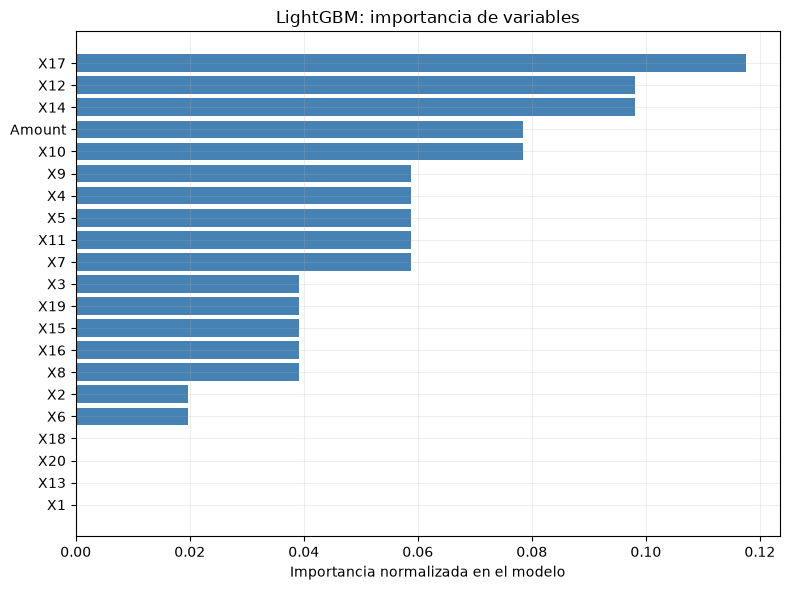

In [13]:
lgb_model = LGBMClassifier(
    n_estimators=MAX_ITERATIONS, num_leaves=15, max_depth=4, learning_rate=0.05,
    subsample=0.8, subsample_freq=1, colsample_bytree=0.9,
    objective="binary", metric="auc", random_state=RANDOM_STATE, n_jobs=N_JOBS,
    device_type="cpu", deterministic=True, force_col_wise=True, verbosity=-1,
)
start = perf_counter()
with threadpool_limits(limits=N_JOBS):
    lgb_model.fit(
        X_train, y_train, eval_X=X_valid, eval_y=y_valid, eval_metric="auc",
        callbacks=[early_stopping(EARLY_STOPPING_ROUNDS, first_metric_only=True, verbose=False), log_evaluation(0)],
    )
elapsed = perf_counter() - start
record_validation("LightGBM", lgb_model, elapsed, lgb_model.best_iteration_)

<a id="comparacion"></a>
## 6. Comparación y selección en validación

Ordenamos por **AP descendente**, después por **ROC-AUC descendente** y, en caso de empate
exacto, por el orden de presentación. No redondeamos las métricas antes de elegir.
Los tiempos describen esta máquina, no son una comparación universal de rendimiento.

La curva Precision-Recall permite valorar precisión y cobertura de fraude cuando la clase
positiva es escasa. La AP de scikit-learn resume esta curva ponderando la precisión por
incrementos de recall; no es el área trapezoidal interpolada. ROC-AUC aporta otra perspectiva,
pero puede resultar optimista ante un fuerte desequilibrio.

,AP,ROC-AUC,Precision@0.5,Recall@0.5,F1@0.5,Iteraciones,Segundos de ajuste
Modelo,,,,,,,
Random Forest,0.798778,0.939061,0.918367,0.762712,0.833333,100,6.496993
XGBoost,0.739782,0.979821,0.000000,0.000000,0.000000,5,0.623802
LightGBM,0.722487,0.917901,0.821429,0.779661,0.800000,5,0.368533
CatBoost,0.708014,0.984679,0.903226,0.474576,0.622222,7,1.262518
AdaBoost,0.683423,0.982459,0.764706,0.661017,0.709091,100,15.137829


Modelo seleccionado sin consultar test: Random Forest (100 estimadores/iteraciones).


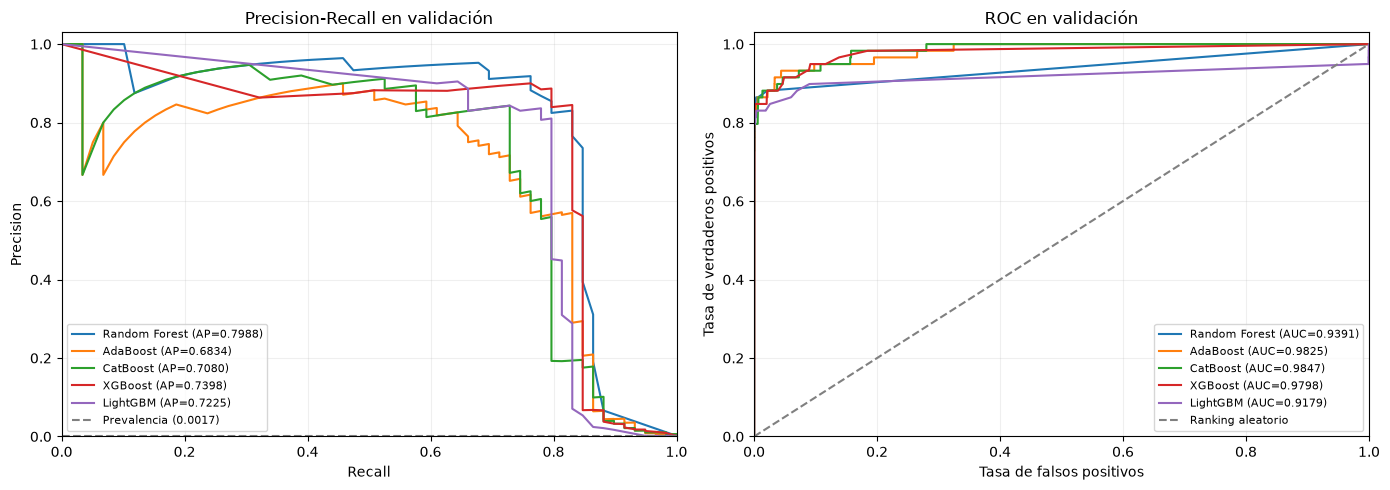

In [14]:
EXPECTED_MODELS = ["Random Forest", "AdaBoost", "CatBoost", "XGBoost", "LightGBM"]
assert list(models) == EXPECTED_MODELS
assert list(validation_scores) == EXPECTED_MODELS
comparison = pd.DataFrame(validation_rows).sort_values(
    ["AP", "ROC-AUC", "Orden"], ascending=[False, False, True], kind="stable"
).reset_index(drop=True)
assert len(comparison) == 5 and comparison["Modelo"].is_unique
display(comparison.drop(columns="Orden").set_index("Modelo").round(6))

winner_name = comparison.iloc[0]["Modelo"]
winner_iterations = selected_iterations[winner_name]
print(f"Modelo seleccionado sin consultar test: {winner_name} ({winner_iterations} estimadores/iteraciones).")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for name in EXPECTED_MODELS:
    scores = validation_scores[name]
    precision, recall, _ = precision_recall_curve(y_valid, scores)
    fpr, tpr, _ = roc_curve(y_valid, scores)
    metrics = comparison.loc[comparison["Modelo"].eq(name)].iloc[0]
    axes[0].plot(recall, precision, label=f"{name} (AP={metrics['AP']:.4f})")
    axes[1].plot(fpr, tpr, label=f"{name} (AUC={metrics['ROC-AUC']:.4f})")
axes[0].axhline(y_valid.mean(), color="gray", linestyle="--", label=f"Prevalencia ({y_valid.mean():.4f})")
axes[1].plot([0, 1], [0, 1], color="gray", linestyle="--", label="Ranking aleatorio")
axes[0].set(xlabel="Recall", ylabel="Precision", title="Precision-Recall en validación", xlim=(0, 1), ylim=(0, 1.03))
axes[1].set(xlabel="Tasa de falsos positivos", ylabel="Tasa de verdaderos positivos", title="ROC en validación", xlim=(0, 1), ylim=(0, 1.03))
for ax in axes:
    ax.legend(fontsize=8, loc="lower left" if ax is axes[0] else "lower right")
fig.tight_layout()
plt.show()

### Matrices de confusión con umbral 0,5

Los scores mayores o iguales a 0,5 se convierten aquí en fraude. Es un umbral ilustrativo,
no optimizado ni justificado por costes de negocio. Las probabilidades no están calibradas
para producción. AP y ROC-AUC se calculan siempre con **scores continuos**, no con estas etiquetas.

Un falso positivo es una operación legítima marcada como fraude; un falso negativo es un fraude
no detectado. La matriz permite ver los recuentos, pero la exactitud global puede ocultar
un mal detector por el predominio de operaciones normales.

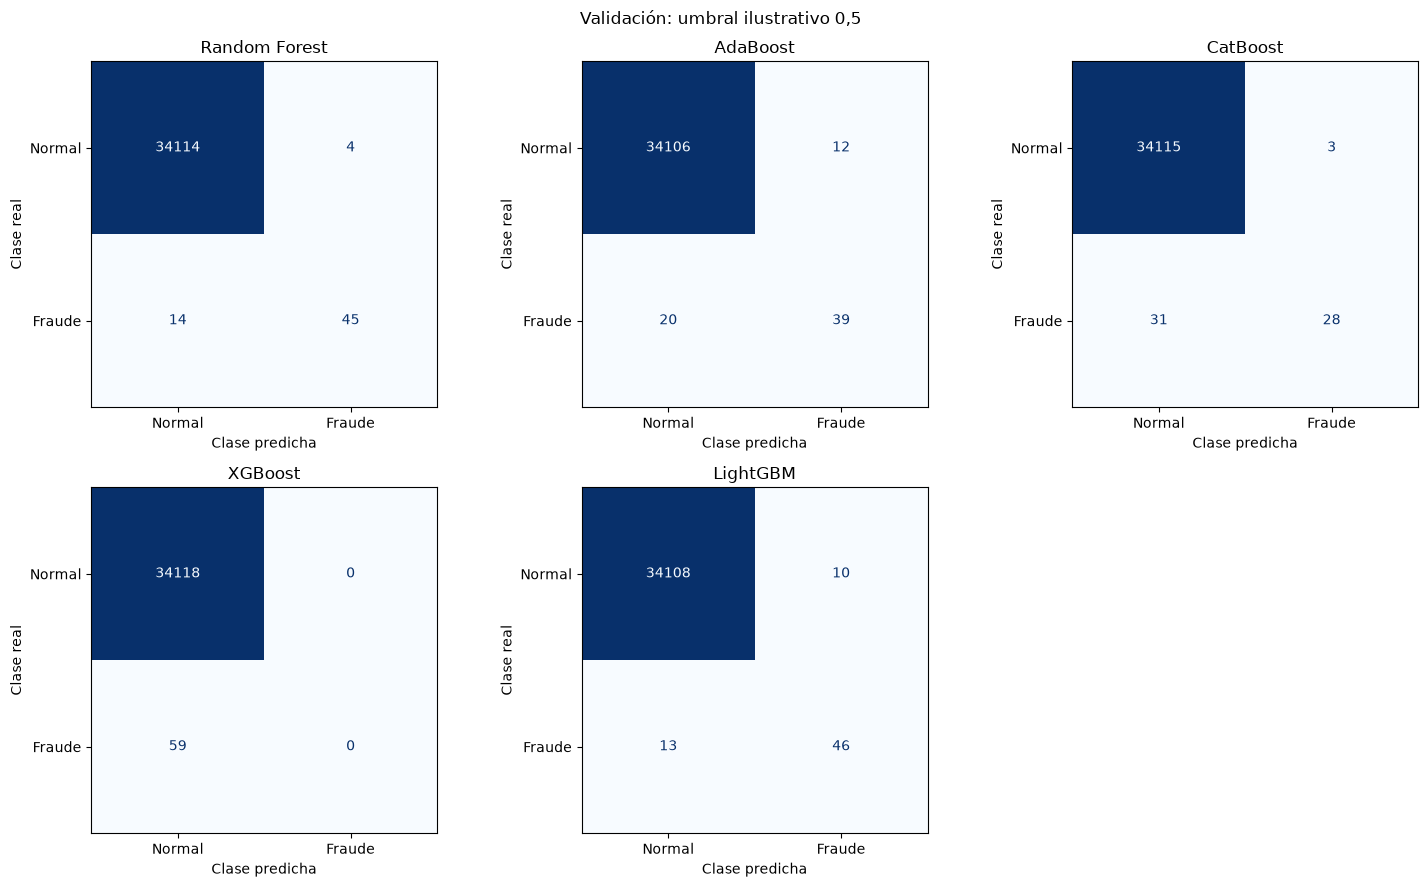

In [15]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for ax, name in zip(axes.flat, EXPECTED_MODELS):
    ConfusionMatrixDisplay.from_predictions(
        y_valid, (validation_scores[name] >= THRESHOLD).astype(int), labels=[0, 1],
        display_labels=["Normal", "Fraude"], cmap="Blues", values_format="d", colorbar=False, ax=ax,
    )
    ax.set(title=name, xlabel="Clase predicha", ylabel="Clase real")
    ax.grid(False)
axes.flat[-1].set_visible(False)
fig.suptitle("Validación: umbral ilustrativo 0,5")
fig.tight_layout()
plt.show()

<a id="test"></a>
## 7. Reentrenamiento y evaluación final en test

La elección del ganador ya está cerrada. Lo clonamos y reentrenamos con **entrenamiento más
validación**, conservando sus hiperparámetros y el número de iteraciones seleccionado.
Desactivamos la parada temprana: test no participa en el ajuste ni sirve para elegir el número
de árboles. AdaBoost puede detenerse antes si encuentra una solución perfecta o no puede continuar.

Calculamos las probabilidades de test **una sola vez** y reutilizamos ese vector para las métricas
y los gráficos. No volvemos a comparar candidatos ni ajustamos el umbral tras ver test.

,Partición,AP,ROC-AUC,Precision@0.5,Recall@0.5,F1@0.5,Iteraciones fijadas,Segundos de ajuste
Modelo,,,,,,,,
Random Forest,Test reservado,0.787099,0.938699,0.930233,0.677966,0.784314,100,11.460487


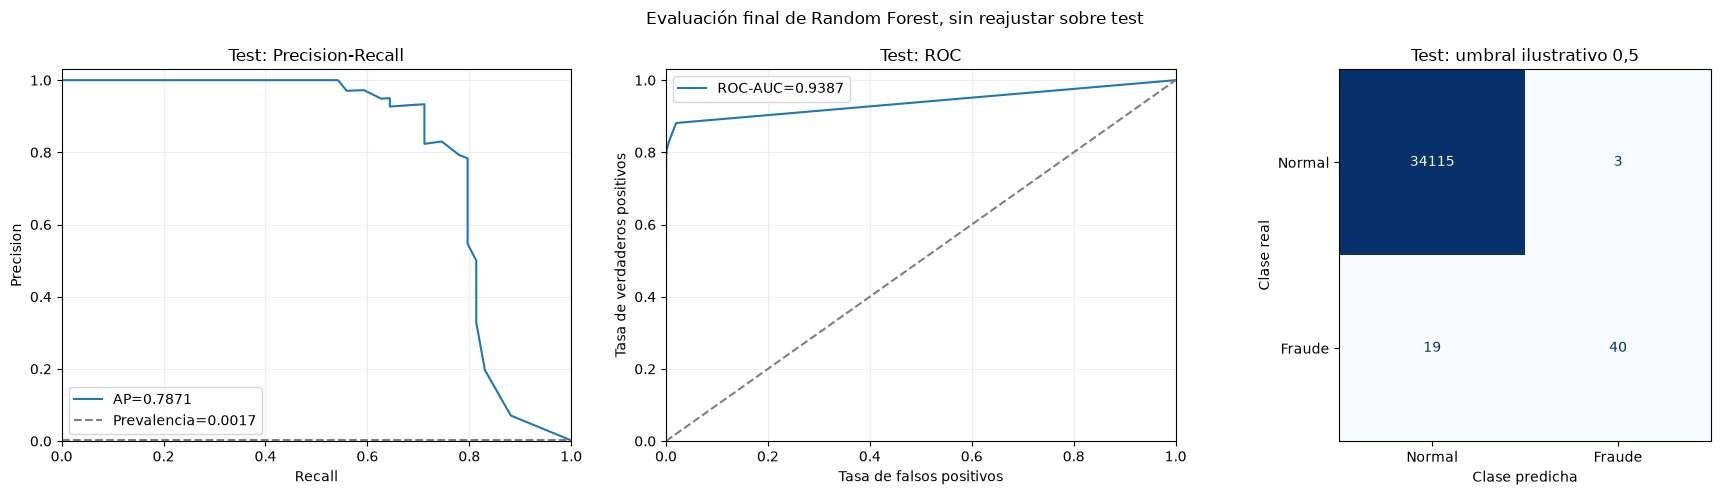

In [16]:
final_model = clone(models[winner_name])
if winner_name == "CatBoost":
    final_model.set_params(iterations=winner_iterations, use_best_model=False)
else:
    final_model.set_params(n_estimators=winner_iterations)
if winner_name == "XGBoost":
    final_model.set_params(early_stopping_rounds=None)

assert selected_iterations[winner_name] == winner_iterations
iteration_parameter = "iterations" if winner_name == "CatBoost" else "n_estimators"
assert final_model.get_params()[iteration_parameter] == winner_iterations
assert set(idx_dev).isdisjoint(idx_test)

start = perf_counter()
with threadpool_limits(limits=N_JOBS):
    final_model.fit(X.iloc[idx_dev], y.iloc[idx_dev])
final_fit_seconds = perf_counter() - start
assert list(final_model.classes_) == [0, 1]

y_test = y.iloc[idx_test]
prediction_kwargs = {"thread_count": N_JOBS} if winner_name == "CatBoost" else {}
test_scores = check_scores(final_model.predict_proba(X.iloc[idx_test], **prediction_kwargs)[:, 1], len(y_test))
test_metrics = measure_scores(y_test, test_scores)
display(pd.DataFrame([{
    "Modelo": winner_name, "Partición": "Test reservado", **test_metrics,
    "Iteraciones fijadas": winner_iterations, "Segundos de ajuste": final_fit_seconds,
}]).set_index("Modelo").round(6))

precision, recall, _ = precision_recall_curve(y_test, test_scores)
fpr, tpr, _ = roc_curve(y_test, test_scores)
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
axes[0].plot(recall, precision, label=f"AP={test_metrics['AP']:.4f}")
axes[0].axhline(y_test.mean(), color="gray", linestyle="--", label=f"Prevalencia={y_test.mean():.4f}")
axes[0].set(xlabel="Recall", ylabel="Precision", title="Test: Precision-Recall", xlim=(0, 1), ylim=(0, 1.03))
axes[0].legend()
axes[1].plot(fpr, tpr, label=f"ROC-AUC={test_metrics['ROC-AUC']:.4f}")
axes[1].plot([0, 1], [0, 1], color="gray", linestyle="--")
axes[1].set(xlabel="Tasa de falsos positivos", ylabel="Tasa de verdaderos positivos", title="Test: ROC", xlim=(0, 1), ylim=(0, 1.03))
axes[1].legend()
ConfusionMatrixDisplay.from_predictions(
    y_test, (test_scores >= THRESHOLD).astype(int), labels=[0, 1],
    display_labels=["Normal", "Fraude"], cmap="Blues", values_format="d", colorbar=False, ax=axes[2],
)
axes[2].set(title="Test: umbral ilustrativo 0,5", xlabel="Clase predicha", ylabel="Clase real")
axes[2].grid(False)
fig.suptitle(f"Evaluación final de {winner_name}, sin reajustar sobre test")
fig.tight_layout()
plt.show()

<a id="conclusiones"></a>
## 8. Conclusiones de esta ejecución

El siguiente resumen se genera con los resultados calculados, sin cifras heredadas de la referencia.

In [17]:
winner_validation = comparison.iloc[0]
ranking_lines = "\n".join(
    f"- **{row['Modelo']}**: AP de validación {row['AP']:.5f}; ROC-AUC {row['ROC-AUC']:.5f}."
    for _, row in comparison.iterrows()
)
display(Markdown(
    f"Se analizaron **{len(df_const):,} transacciones**, con **{int(y.sum())} fraudes** "
    f"({100 * y.mean():.4f} %). Se conservaron las **{int(df_const.duplicated().sum()):,} filas "
    "duplicadas adicionales**, manteniendo cada grupo en una única partición.\n\n"
    f"Resultados de los cinco modelos en validación:\n\n{ranking_lines}\n\n"
    f"El ganador por AP fue **{winner_name}**, con **{winner_iterations} iteraciones/estimadores** "
    f"seleccionados y AP de validación **{winner_validation['AP']:.5f}**. "
    "Tras reentrenarlo con entrenamiento y validación, obtuvo en el test reservado "
    f"**AP = {test_metrics['AP']:.5f}** y **ROC-AUC = {test_metrics['ROC-AUC']:.5f}**. "
    f"La prevalencia de fraude en test fue **{y_test.mean():.5f}**.\n\n"
    "Con el umbral ilustrativo 0,5, la precisión en test fue "
    f"**{test_metrics['Precision@0.5']:.5f}** y el recall **{test_metrics['Recall@0.5']:.5f}**. "
    "Ese umbral no se ha optimizado.\n\n"
    "Estos resultados corresponden a una sola partición agrupada de construcción y a las "
    "configuraciones probadas. La escasez de fraudes y la selección sobre validación introducen "
    "incertidumbre; una diferencia entre validación y test no prueba por sí sola un cambio "
    "de distribución. No estiman el rendimiento sobre producción ni sobre fraudes nuevos."
))

Se analizaron **170,884 transacciones**, con **295 fraudes** (0.1726 %). Se conservaron las **4,167 filas duplicadas adicionales**, manteniendo cada grupo en una única partición.

Resultados de los cinco modelos en validación:

- **Random Forest**: AP de validación 0.79878; ROC-AUC 0.93906.
- **XGBoost**: AP de validación 0.73978; ROC-AUC 0.97982.
- **LightGBM**: AP de validación 0.72249; ROC-AUC 0.91790.
- **CatBoost**: AP de validación 0.70801; ROC-AUC 0.98468.
- **AdaBoost**: AP de validación 0.68342; ROC-AUC 0.98246.

El ganador por AP fue **Random Forest**, con **100 iteraciones/estimadores** seleccionados y AP de validación **0.79878**. Tras reentrenarlo con entrenamiento y validación, obtuvo en el test reservado **AP = 0.78710** y **ROC-AUC = 0.93870**. La prevalencia de fraude en test fue **0.00173**.

Con el umbral ilustrativo 0,5, la precisión en test fue **0.93023** y el recall **0.67797**. Ese umbral no se ha optimizado.

Estos resultados corresponden a una sola partición agrupada de construcción y a las configuraciones probadas. La escasez de fraudes y la selección sobre validación introducen incertidumbre; una diferencia entre validación y test no prueba por sí sola un cambio de distribución. No estiman el rendimiento sobre producción ni sobre fraudes nuevos.

### Referencias y decisiones de adaptación

- [Notebook de referencia local](credit-card-fraud-detection-predictive-models.ipynb): estructura exploratoria y familias de modelos.
- [Taller local](taller_detección_anomalías.ipynb): carga del ZIP, predictores, etiquetas y objetivo AUPR.
- [Average Precision](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.average_precision_score.html): AP con scores continuos y clase positiva 1.
- [StratifiedGroupKFold](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.StratifiedGroupKFold.html): reparto con grupos sin solapamientos y aproximación a la proporción de clases.
- [CatBoost: entrenamiento](https://catboost.ai/docs/en/concepts/python-reference_catboostclassifier_fit): validación, parada temprana y conservación del mejor modelo.
- [XGBoost: API Python](https://xgboost.readthedocs.io/en/stable/python/python_api.html): API de `XGBClassifier`, parada temprana y mejor iteración.
- [LightGBM: LGBMClassifier](https://lightgbm.readthedocs.io/en/stable/pythonapi/lightgbm.LGBMClassifier.html): entrenamiento y predicción con la mejor iteración.

No se reproducen la exploración temporal, los resultados numéricos ni las API antiguas de la referencia.
No se realiza búsqueda exhaustiva, validación cruzada ni selección adicional después de consultar test.

<a id="produccion"></a>
## 9. Scores de producción y CSV para el profesor

La comparación y el test interno anteriores ya están cerrados. Este envío fija **Random Forest
con 100 árboles**, el ganador por AP de validación, sin ajustar su configuración a partir de test.
El AP mostrado en la sección anterior corresponde al test de construcción; no es una medida
del rendimiento en producción ni del modelo reentrenado con todos los datos.

Ahora cargamos producción, creamos un modelo independiente entrenado con **todo construcción**
y calculamos una probabilidad estimada de fraude por transacción. Los valores más altos indican
mayor evidencia de fraude. No se aplica umbral ni se ordenan las filas por score.
No disponemos de etiquetas de producción para calcular su AP; esa evaluación corresponde al profesor.

### 9.1. Carga y validación de producción

Se mantiene el orden de lectura y se seleccionan exactamente los mismos 21 predictores,
en el mismo orden que durante el desarrollo. La columna `Class` del fichero viene vacía
y se excluye de los predictores. El ZIP disponible contiene **113.923 transacciones**;
se usa ese número real, aunque el enunciado mencione 113.223.

In [18]:
PRODUCTION_PATH = PROJECT_ROOT / "data" / "credit_card_production.csv.zip"
EXPECTED_PRODUCTION_ROWS = 113_923
if not PRODUCTION_PATH.is_file():
    raise FileNotFoundError(f"No se encuentra el ZIP de producción: {PRODUCTION_PATH}")

df_prod = pd.read_csv(PRODUCTION_PATH, compression="zip", low_memory=False)
assert df_prod.columns.is_unique, "Hay nombres de columna duplicados en producción."
assert set(PREDICTORS).issubset(df_prod.columns), "Faltan predictores en producción."
assert not (set(df_prod.columns) - set(PREDICTORS + [TARGET])), "Hay columnas inesperadas en producción."
assert len(df_prod) == EXPECTED_PRODUCTION_ROWS, "El tamaño de producción ha cambiado: revisar el envío."
if TARGET in df_prod.columns:
    assert df_prod[TARGET].isna().all(), "Se esperaba una columna Class vacía en producción."

X_prod = df_prod.loc[:, PREDICTORS]
assert X_prod.columns.tolist() == X.columns.tolist()
assert X_prod.index.equals(pd.RangeIndex(len(df_prod))), "Debe mantenerse el orden de lectura."
assert all(pd.api.types.is_numeric_dtype(X_prod[column]) for column in PREDICTORS)
assert not X_prod.isna().any().any(), "Hay nulos en los predictores de producción."
assert np.isfinite(X_prod.to_numpy()).all(), "Hay valores no finitos en producción."

print(f"Producción comprobada: {len(X_prod):,} transacciones y {X_prod.shape[1]} predictores.")
print("Class excluida; se conserva el orden original del fichero, sin eliminar filas.")
display(X_prod.head())

Producción comprobada: 113,923 transacciones y 21 predictores.
Class excluida; se conserva el orden original del fichero, sin eliminar filas.


,X1,X2,X3,X4,X5,X6,X7,X8,X9,X10,X11,X12,X13,X14,X15,X16,X17,X18,X19,X20,Amount
0,234.0,48.0,58.0,106.0,-30.0,-56.0,-22.0,20.0,-38.0,-30.0,360.0,172.0,-32.0,-2.0,136.0,80.0,8.0,-44.0,-52.0,-24.0,1.94
1,408.0,-126.0,-426.0,-312.0,12.0,-238.0,56.0,-48.0,292.0,-136.0,154.0,118.0,-372.0,204.0,-48.0,-214.0,-4.0,24.0,270.0,-44.0,60.68
2,-150.0,84.0,580.0,-326.0,-86.0,-100.0,74.0,-32.0,494.0,-418.0,228.0,-348.0,334.0,184.0,30.0,-172.0,142.0,-28.0,-144.0,-18.0,17.77
3,296.0,-134.0,-388.0,132.0,-12.0,-228.0,114.0,-70.0,44.0,-88.0,304.0,208.0,82.0,-112.0,34.0,78.0,32.0,192.0,-54.0,78.0,416.38
4,-594.0,-214.0,414.0,308.0,38.0,196.0,-46.0,62.0,70.0,98.0,270.0,32.0,-202.0,-34.0,236.0,-86.0,42.0,28.0,100.0,-222.0,138.00


### 9.2. Modelo para el envío: reentrenar con todo construcción

Clonamos la configuración del modelo evaluado, manteniendo 100 árboles, semilla 42 y cuatro hilos.
El nuevo objeto `production_model` se ajusta con todas las transacciones etiquetadas.
`final_model` conserva el ajuste utilizado para el test interno. No recalculamos métricas
sobre ese test con el nuevo modelo, porque sus filas ahora forman parte del entrenamiento.

In [19]:
assert winner_name == "Random Forest", "El ganador de validación ha cambiado: revisar la configuración del envío."
assert winner_iterations == 100
assert isinstance(final_model, RandomForestClassifier)

production_model = clone(final_model)
assert production_model is not final_model
assert production_model.get_params() == final_model.get_params()
assert production_model.n_estimators == 100
assert production_model.random_state == RANDOM_STATE == 42
assert production_model.n_jobs == N_JOBS == 4
assert len(X) == len(df_const) and y.index.equals(X.index)

start = perf_counter()
with threadpool_limits(limits=N_JOBS):
    production_model.fit(X, y)
production_fit_seconds = perf_counter() - start
assert list(production_model.classes_) == [0, 1]
assert production_model.feature_names_in_.tolist() == PREDICTORS
assert len(production_model.estimators_) == 100

production_scores = check_scores(production_model.predict_proba(X_prod)[:, 1], len(X_prod))
display(pd.DataFrame([{
    "Modelo para envío": winner_name,
    "Transacciones de entrenamiento": len(X),
    "Árboles": production_model.n_estimators,
    "Semilla": production_model.random_state,
    "Hilos": production_model.n_jobs,
    "Transacciones puntuadas": len(production_scores),
    "Segundos de ajuste": production_fit_seconds,
}]))

,Modelo para envío,Transacciones de entrenamiento,Árboles,Semilla,Hilos,Transacciones puntuadas,Segundos de ajuste
0,Random Forest,170884,100,42,4,113923,16.279825


### 9.3. Exportación y comprobación del CSV

Generamos `outputs/scores_produccion_random_forest.csv`: **una columna numérica sin cabecera
ni índice**, con una fila por transacción en el orden original. Se escribe con precisión
suficiente para recuperar exactamente los scores y se valida volviendo a leer el archivo.
Al repetir la sección se actualiza ese mismo CSV. La regla `*.csv` del repositorio lo excluye de Git.

In [20]:
OUTPUT_DIR = PROJECT_ROOT / "outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
SUBMISSION_PATH = OUTPUT_DIR / "scores_produccion_random_forest.csv"

pd.DataFrame({"score": production_scores}).to_csv(
    SUBMISSION_PATH, header=False, index=False, float_format="%.17g",
)
submission_check = pd.read_csv(SUBMISSION_PATH, header=None, float_precision="round_trip")
assert submission_check.shape == (len(X_prod), 1) == (EXPECTED_PRODUCTION_ROWS, 1)
assert pd.api.types.is_numeric_dtype(submission_check[0])
saved_scores = check_scores(submission_check[0].to_numpy(), len(X_prod))
np.testing.assert_array_equal(saved_scores, production_scores)

print(f"CSV listo para enviar: {SUBMISSION_PATH.resolve()}")
print(f"Verificado: {len(saved_scores):,} filas, una columna numérica, sin cabecera ni índice.")
print("Scores finitos entre 0 y 1, idénticos y en el mismo orden que la predicción de producción.")
display(pd.Series(saved_scores, name="score").describe().to_frame())

CSV listo para enviar: C:\Users\O013392\Desktop\MIAX\deteccion_outliers_fraude\outputs\scores_produccion_random_forest.csv
Verificado: 113,923 filas, una columna numérica, sin cabecera ni índice.
Scores finitos entre 0 y 1, idénticos y en el mismo orden que la predicción de producción.


,score
count,113923.000000
mean,0.001645
std,0.033152
min,0.000000
25%,0.000000
50%,0.000000
75%,0.000000
max,1.000000
